# **MODELO DE CLASIFICACIÓN 1:**
# **Árbol de Decisión (** DecisionTreeClassifier **)**

Es modelo de ábol de desición es un modelo de "caja blanca" en el que al final, se puede  visualizar un diagrama de flujo de las "preguntas" que el modelo aprendió a hacer, lo cual es muy intuitivo.


****
## **Paso 0: Introducción y Librerías**

**Objetivo:** Entrenar un modelo que pueda predecir la especie de un pingüino basándose en sus medidas físicas (largo y profundidad del pico, largo de la aleta y masa corporal). Usaremos un **Árbol de Decisión**, un modelo fácil de interpretar.

In [24]:
# Librerías para cargar el dataset y construir gráficos
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [25]:
# Librerías necesarias para el modelo DecisionTreeClassifier
from sklearn.model_selection import train_test_split, GridSearchCV

In [26]:
# Métricas de rendimiento
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [27]:
# Librerías para graficar el árbol de desición
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import plot_tree

****
## **Paso 1: Cargar los datos**

In [28]:
df = pd.read_csv('df_cleaned.csv')
df.head()

,carat,cut,depth,table,price,x,y,z,Color_D,Color_E,...,Color_I,Color_J,Cl_I1,Cl_IF,Cl_SI1,Cl_SI2,Cl_VS1,Cl_VS2,Cl_VVS1,Cl_VVS2
0,0.23,Ideal,61.5,55.0,326,3.95,3.98,2.43,False,True,...,False,False,False,False,False,True,False,False,False,False
1,0.21,Premium,59.8,61.0,326,3.89,3.84,2.31,False,True,...,False,False,False,False,True,False,False,False,False,False
2,0.23,Good,56.9,65.0,327,4.05,4.07,2.31,False,True,...,False,False,False,False,False,False,True,False,False,False
3,0.29,Premium,62.4,58.0,334,4.20,4.23,2.63,False,False,...,True,False,False,False,False,False,False,True,False,False
4,0.31,Good,63.3,58.0,335,4.34,4.35,2.75,False,False,...,False,True,False,False,False,True,False,False,False,False


***
## **Paso 2: Cargar y Explorar los Datos**
## **Paso 3: Preparación de Datos (Limpieza de datos)**

Vamos a omitir estos pasos, ya que se realizaron durante la limpieza

***
## **Paso 4: Definir Features (X) y Target (y)**

Ahora, separamos nuestros datos en dos partes:

* **Features (`X`):** Las variables de entrada, las "preguntas" que le damos al modelo. Usaremos solo las medidas numéricas.

* **Target (`y`):** La variable de salida, la "respuesta" que queremos predecir (En este caso, las columna `species`).

In [29]:
df.head()

,carat,cut,depth,table,price,x,y,z,Color_D,Color_E,...,Color_I,Color_J,Cl_I1,Cl_IF,Cl_SI1,Cl_SI2,Cl_VS1,Cl_VS2,Cl_VVS1,Cl_VVS2
0,0.23,Ideal,61.5,55.0,326,3.95,3.98,2.43,False,True,...,False,False,False,False,False,True,False,False,False,False
1,0.21,Premium,59.8,61.0,326,3.89,3.84,2.31,False,True,...,False,False,False,False,True,False,False,False,False,False
2,0.23,Good,56.9,65.0,327,4.05,4.07,2.31,False,True,...,False,False,False,False,False,False,True,False,False,False
3,0.29,Premium,62.4,58.0,334,4.20,4.23,2.63,False,False,...,True,False,False,False,False,False,False,True,False,False
4,0.31,Good,63.3,58.0,335,4.34,4.35,2.75,False,False,...,False,True,False,False,False,True,False,False,False,False


* Definimos la columna (o lista de columnas) que será nuestro target `y`

In [30]:
y = df['cut']     # y es una Serie (con un corchete)
y.head()

,cut
0,Ideal
1,Premium
2,Good
3,Premium
4,Good


* Lista de columnas que usaremos como features y definimos `X`

In [31]:
X = df[df.columns.drop('cut')] # X debe ser un DataFrame (con doble corchete)
X.head()

,carat,depth,table,price,x,y,z,Color_D,Color_E,Color_F,...,Color_I,Color_J,Cl_I1,Cl_IF,Cl_SI1,Cl_SI2,Cl_VS1,Cl_VS2,Cl_VVS1,Cl_VVS2
0,0.23,61.5,55.0,326,3.95,3.98,2.43,False,True,False,...,False,False,False,False,False,True,False,False,False,False
1,0.21,59.8,61.0,326,3.89,3.84,2.31,False,True,False,...,False,False,False,False,True,False,False,False,False,False
2,0.23,56.9,65.0,327,4.05,4.07,2.31,False,True,False,...,False,False,False,False,False,False,True,False,False,False
3,0.29,62.4,58.0,334,4.20,4.23,2.63,False,False,False,...,True,False,False,False,False,False,False,True,False,False
4,0.31,63.3,58.0,335,4.34,4.35,2.75,False,False,False,...,False,True,False,False,False,True,False,False,False,False


In [32]:
# Mostramos las "clases" o especies únicas que el modelo debe aprender
print(f"Clases a predecir: {y.unique()}")

Clases a predecir: ['Ideal' 'Premium' 'Good' 'Very Good' 'Fair']


***
## **Paso 5: Dividir los datos en Train y Test**

Este es el paso más importante del Machine Learning. El set de datos se divide entre datos para entrenar el modelo y el resto para evaluarlo. Generalmente la relación entre datos de entrenamiento y evaluación es **80-20%** o **70-30%**.

* **Set de Entrenamiento (Train):** Lo usaremos para "entrenar" al modelo (80% de los datos).

*  **Set de Prueba (Test):** Lo guardaremos para "evaluar" al modelo con datos que nunca ha visto (20% de los datos).

* Usamos `random_state=42` para que la división aleatoria sea siempre la misma (reproducible).

In [33]:
# Dividimos los datos (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Total de datos de entrenamiento (train): {len(X_train)}")
print(f"Total de datos de prueba (test): {len(X_test)}")

Total de datos de entrenamiento (train): 42988
Total de datos de prueba (test): 10748


***
## **Paso 6: Crear y Entrenar el Modelo**

Inicializamos el modelo **DecisionTreeClassifier**. Usamos `max_depth=3` para limitar la profundidad del árbol a 3 niveles. Esto evita que se vuelva demasiado complejo (sobreajuste) y lo hace fácil de visualizar.

* Entrenamos el modelo usando el método `.fit()` solo con los datos de entrenamiento.

In [34]:
# 1. Inicializar el modelo
tree_model = DecisionTreeClassifier(max_depth=3, random_state=42)

# 2. Entrenar el modelo
tree_model.fit(X_train, y_train)

DecisionTreeClassifier(max_depth=5, random_state=42)

## <font color="red">**CUIDADO**</font>

* El modelo ya está entrenado. La siguiente celda la usaremos SOLO para evaluar cuanto demora en entrenarse el modelo. **No es necesaria** para ejecutar el modelo

In [35]:
%%timeit
tree_model.fit(X_train, y_train)

277 ms ± 45.7 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)


****
## **Paso 7: Evaluar el Modelo**

Ahora, usamos los datos de prueba (**X_test**) que el modelo nunca vio.

1. Hacemos predicciones con los datos de prueba usando `.predict()`

In [36]:
y_pred = tree_model.predict(X_test)

2. Comparamos esas predicciones (**y_pred**) con las respuestas correctas(**y_test**). Primero calculamos la **precisión** usando `.accuracy_score()`:

In [37]:
accuracy = accuracy_score(y_test, y_pred)
print(f"Precisión (Accuracy) del modelo: {accuracy * 100:.1f}%")

Precisión (Accuracy) del modelo: 72.8%


3. Comparamos esas predicciones (**y_pred**) con las respuestas correctas(**y_test**). Ahora calculamos la **matriz de confusión** usando usando `.confusion_matrix()`:

In [38]:
print("--- Matriz de Confusión ---")
print("\n(Las filas son el valor REAL, las columnas la PREDICCIÓN) \n")
labels = tree_model.classes_
cm = confusion_matrix(y_test, y_pred, labels=labels)

# La mostramos como un DataFrame para que sea más fácil de leer
cm_df = pd.DataFrame(cm, index=labels, columns=labels)
print(cm_df)


--- Matriz de Confusión ---

(Las filas son el valor REAL, las columnas la PREDICCIÓN) 

           Fair  Good  Ideal  Premium  Very Good
Fair        275    18      5       13          4
Good         29   546     26      175        213
Ideal         3     8   3891      250        111
Premium       0     0    318     2397         55
Very Good     1   102    616      981        711


***
## **Paso 8: Importancia de las Características (** Feature Importance **)**

* Obtenemos las importancias y creamos una serie de Pandas para verlas fácilmente


In [39]:
importances = tree_model.feature_importances_
feature_names = X_train.columns
forest_importances = pd.Series(importances, index=feature_names)

# Ordenamos de mayor a menor importancia
forest_importances_sorted = forest_importances.sort_values(ascending=False)

print("--- Importancia de las Características (Random Forest) ---\n")
print(forest_importances_sorted)

--- Importancia de las Características (Random Forest) ---

table      0.541856
depth      0.434794
x          0.018839
price      0.002708
carat      0.001168
z          0.000636
y          0.000000
Color_D    0.000000
Color_E    0.000000
Color_F    0.000000
Color_G    0.000000
Color_H    0.000000
Color_I    0.000000
Color_J    0.000000
Cl_I1      0.000000
Cl_IF      0.000000
Cl_SI1     0.000000
Cl_SI2     0.000000
Cl_VS1     0.000000
Cl_VS2     0.000000
Cl_VVS1    0.000000
Cl_VVS2    0.000000
dtype: float64


* Creamos un gráfico de barras para visualizar el resultado más facilmente

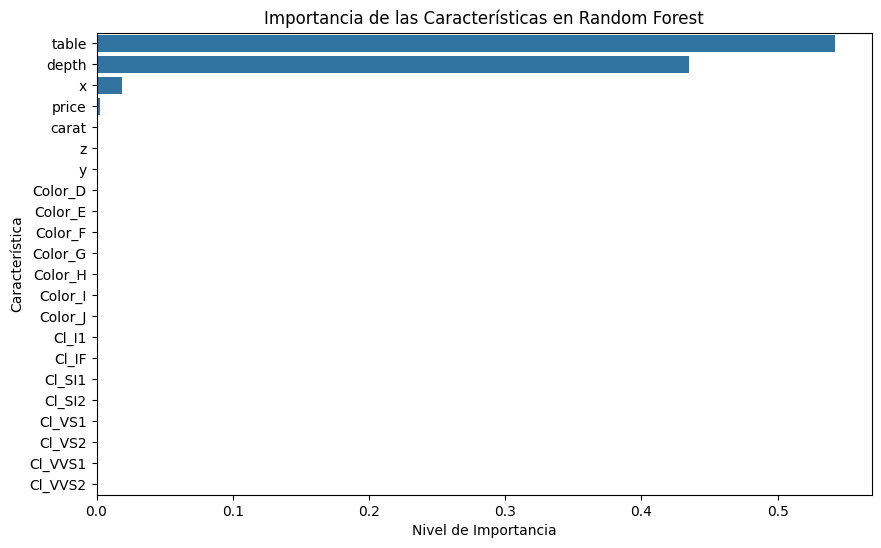

In [40]:
plt.figure(figsize=(10, 6))
sns.barplot(x=forest_importances_sorted.values, y=forest_importances_sorted.index)
plt.title("Importancia de las Características en Random Forest")
plt.xlabel("Nivel de Importancia")
plt.ylabel("Característica")
plt.show()

***
## **Paso 9: Visualizar el Árbol de Decisión**

Esta es la forma más común y útil de interpretar un Random Forest. El modelo puede decirte qué características (**features**) fueron las más importantes (las que más ayudaron a reducir el error) para tomar decisiones en el conjunto del bosque. Es una visión global de qué entradas son clave.

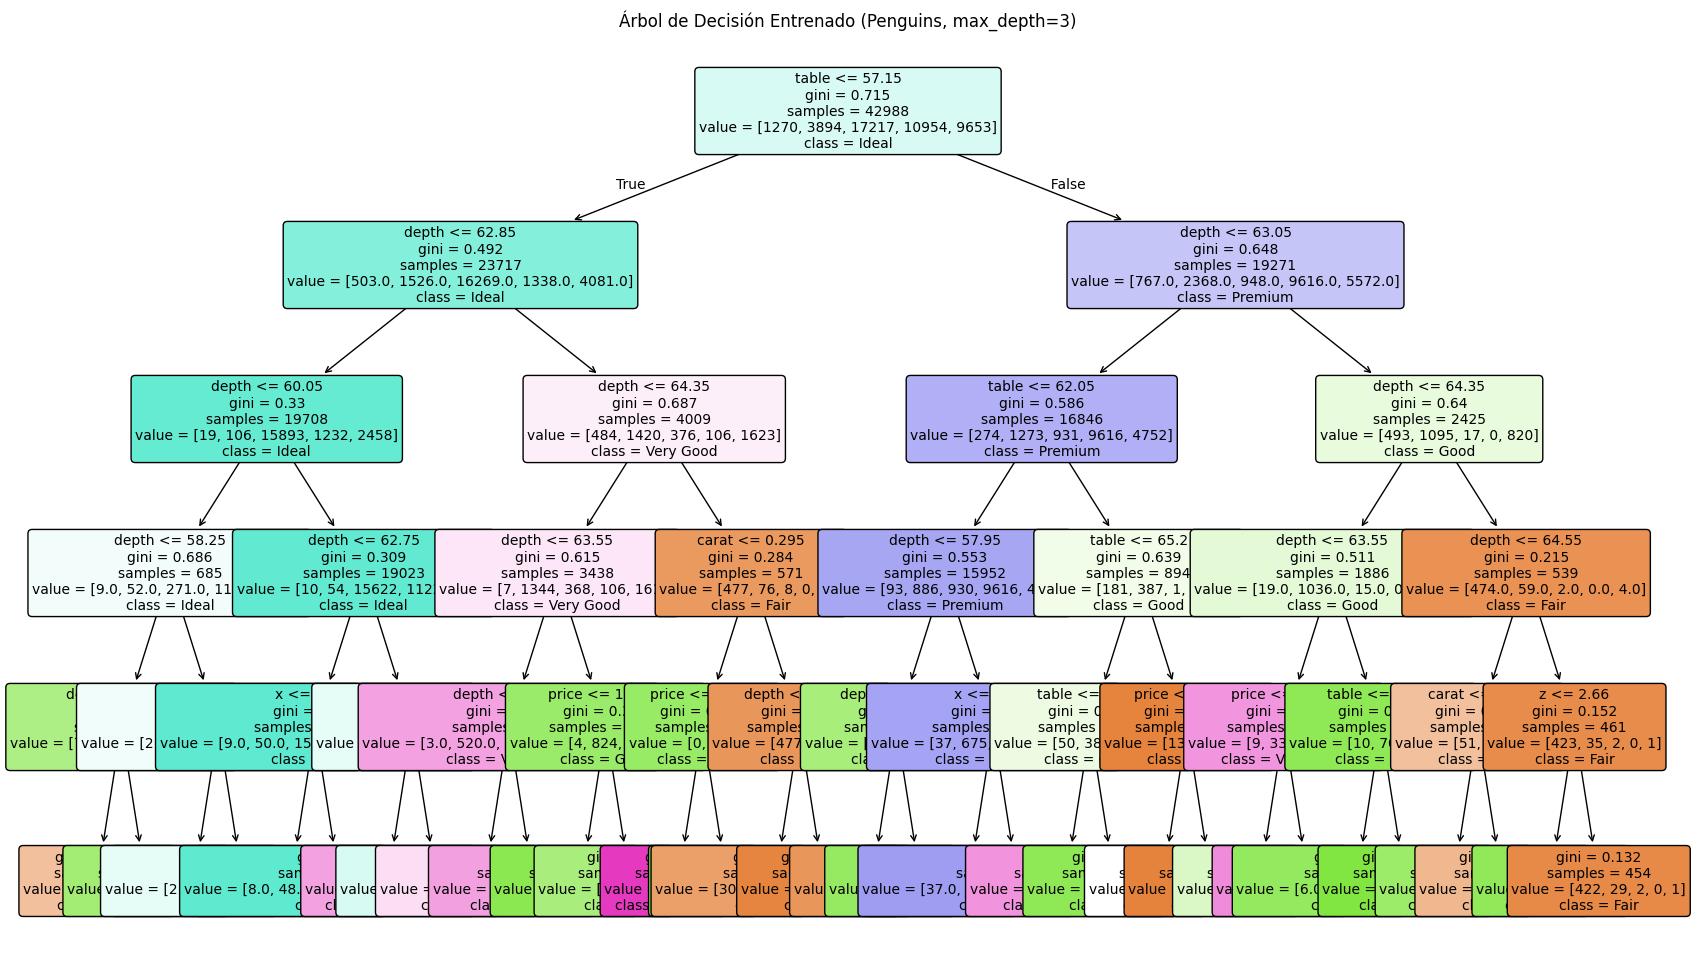

In [41]:
# Preparamos la figura para el gráfico
plt.figure(figsize=(20, 12))

# Usamos la función plot_tree
plot_tree(tree_model, feature_names=df.columns.drop('cut'), class_names=labels, filled=True, rounded=True, fontsize=10)
plt.title("Árbol de Decisión Entrenado (Penguins, max_depth=3)")
plt.savefig("arbol_decision_penguins.png") # Guardar la imagen
plt.show() # Mostrar el gráfico

          feature_names=features_list,       # Nombres de las features
          class_names=labels,                # Nombres de las clases (especies)
          filled=True,                       # Colorear los nodos
          rounded=True,                      # Bordes redondeados